# Sales Performance Analysis: Sample Superstore

**Goal:** analyse four years of US retail orders to find revenue trends, top-performing products,
customer purchasing behaviour and regional performance, and turn them into business recommendations.

**Dataset:** Tableau's *Sample - Superstore* (9,994 order lines, Jan 2015 to Dec 2018), an office-supplies,
furniture and technology retailer selling across the United States.

**Contents**
1. Setup
2. Load and inspect the raw data
3. Data cleaning and preprocessing
4. Sales KPI analysis
5. Revenue trends and seasonality
6. Regional sales analysis
7. Product performance
8. Customer purchasing behaviour
9. Discounts and profitability
10. Business insights and recommendations

## 1. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import cleaning

IMG = ROOT / "images"
IMG.mkdir(exist_ok=True)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 40)

# One consistent palette: blue = revenue / positive, orange = profit, red = loss.
BLUE, ORANGE, RED, GREY = "#2a78d6", "#eb6834", "#e34948", "#898781"
plt.rcParams.update({
    "figure.figsize": (10, 4.2), "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "xtick.color": "#52514e", "ytick.color": "#52514e",
})
money = mtick.FuncFormatter(lambda v, _: f"${v/1e3:,.0f}K" if abs(v) >= 1e3 else f"${v:,.0f}")

## 2. Load and inspect the raw data

In [2]:
raw = cleaning.load_raw()
print(raw.shape)
raw.head()

(10800, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,"42,420.00",South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2.00,0.00,41.91
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,"42,420.00",South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3.00,0.00,219.58
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,"90,036.00",West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2.00,0.00,6.87
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,"33,311.00",South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5.00,0.45,-383.03
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,"33,311.00",South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2.00,0.20,2.52


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  str    
 1   Order ID       10800 non-null  str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       99

The file has **10,800 rows but only 9,994 order lines**. Looking at the tail shows why: the source Excel
workbook's two other sheets (regional managers and returned orders) were flattened into the same CSV
underneath the orders. They need to be split out before any analysis.

In [4]:
raw.iloc[9990:10005, :4]

,Row ID,Order ID,Order Date,Ship Date
9990,9991,CA-2018-121258,2/26/2018,3/3/2018
9991,9992,CA-2018-121258,2/26/2018,3/3/2018
9992,9993,CA-2018-121258,2/26/2018,3/3/2018
9993,9994,CA-2018-119914,5/4/2018,5/9/2018
9994,Person,Region,NaN,NaN
9995,Anna Andreadi,West,NaN,NaN
9996,Chuck Magee,East,NaN,NaN
9997,Kelly Williams,Central,NaN,NaN
9998,Cassandra Brandow,South,NaN,NaN
9999,Returned,Order ID,NaN,NaN


In [5]:
print("Missing values per column (order lines only):")
raw.iloc[:9994].isna().sum()[lambda s: s > 0]

Missing values per column (order lines only):


Postal Code    11
dtype: int64

## 3. Data cleaning and preprocessing

All cleaning lives in [`src/cleaning.py`](../src/cleaning.py) so the notebook, dashboard and report use
the same logic. Steps:

| Step | Issue found | Action |
|---|---|---|
| Split tables | Managers and returns appended under the orders | Separate into `orders`, `people`, `returns` |
| Types | Dates stored as `m/d/yyyy` text, Row ID as text | Parse dates, cast IDs and quantities to int |
| Missing values | 11 blank postal codes, all Burlington, VT | Fill with 05401, store as 5-digit text |
| Duplicates | 1 order line repeated exactly | Drop it |
| Validation | Ship before order? Out-of-range discount? | Assert none exist |
| Features | Analysis needs time parts and ratios | Year, quarter, month, days-to-ship, margin, unit price, discount band, returned flag, regional manager |

In [6]:
orders, people, returns = cleaning.split_tables(raw)
log = []
df = cleaning.clean_orders(orders, returns, people, log)
print("\n".join(log))
df.to_csv(ROOT / "data/processed/superstore_clean.csv", index=False, date_format="%Y-%m-%d")
people

Filled 11 missing postal codes (Burlington, VT -> 05401)
Removed 1 duplicate order line(s)
Clean table: 9,993 rows x 33 columns


,Regional Manager,Region
0,Anna Andreadi,West
1,Chuck Magee,East
2,Kelly Williams,Central
3,Cassandra Brandow,South


In [7]:
df.dtypes

Row ID                       int64
Order ID                       str
Order Date          datetime64[us]
Ship Date           datetime64[us]
Ship Mode                      str
Customer ID                    str
Customer Name                  str
Segment                        str
Country                        str
City                           str
State                          str
Postal Code                    str
Region                         str
Product ID                     str
Category                       str
Sub-Category                   str
Product Name                   str
Sales                      float64
Quantity                     int64
Discount                   float64
Profit                     float64
Returned                      bool
Regional Manager               str
Year                         int32
Quarter                      int32
Month                        int32
Order Month         datetime64[us]
Weekday                        str
Days to Ship        

In [8]:
df[["Sales", "Quantity", "Discount", "Profit", "Days to Ship", "Profit Margin"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Sales,"9,993.00",229.85,623.28,0.44,17.28,54.48,209.94,"22,638.48"
Quantity,"9,993.00",3.79,2.23,1.00,2.00,3.00,5.00,14.00
Discount,"9,993.00",0.16,0.21,0.00,0.00,0.20,0.20,0.80
Profit,"9,993.00",28.66,234.27,"-6,599.98",1.73,8.67,29.36,"8,399.98"
Days to Ship,"9,993.00",3.96,1.75,0.00,3.00,4.00,5.00,7.00
Profit Margin,"9,993.00",0.12,0.47,-2.75,0.07,0.27,0.36,0.50


**Outliers.** Sales and profit are heavily right-skewed (median sale about \$54, max \$22.6K) and
profit has a long negative tail. These are real transactions such as large copier and table orders, not
entry errors, so they are kept. The analysis uses totals and medians rather than means where it matters.

## 4. Sales KPI analysis

In [9]:
def kpis(d):
    orders_n = d["Order ID"].nunique()
    return pd.Series({
        "Revenue": d["Sales"].sum(),
        "Profit": d["Profit"].sum(),
        "Profit margin": d["Profit"].sum() / d["Sales"].sum(),
        "Orders": orders_n,
        "Customers": d["Customer ID"].nunique(),
        "Units sold": d["Quantity"].sum(),
        "Avg order value": d["Sales"].sum() / orders_n,
        "Return rate (orders)": d.loc[d["Returned"], "Order ID"].nunique() / orders_n,
    })

overall = kpis(df)
overall.to_frame("All years")

,All years
Revenue,"2,296,919.49"
Profit,"286,409.08"
Profit margin,0.12
Orders,"5,009.00"
Customers,793.00
Units sold,"37,871.00"
Avg order value,458.56
Return rate (orders),0.06


In [10]:
yearly = df.groupby("Year").apply(kpis, include_groups=False)
yearly["Revenue growth"] = yearly["Revenue"].pct_change()
yearly["Profit growth"] = yearly["Profit"].pct_change()
yearly

,Revenue,Profit,Profit margin,Orders,Customers,Units sold,Avg order value,Return rate (orders),Revenue growth,Profit growth
Year,,,,,,,,,,
2015,"483,966.13","49,556.03",0.10,969.00,595.00,"7,579.00",499.45,0.05,NaN,NaN
2016,"470,532.51","61,618.60",0.13,"1,038.00",573.00,"7,979.00",453.31,0.06,-0.03,0.24
2017,"609,205.60","81,795.17",0.13,"1,315.00",638.00,"9,837.00",463.27,0.06,0.29,0.33
2018,"733,215.26","93,439.27",0.13,"1,687.00",693.00,"12,476.00",434.63,0.06,0.20,0.14


In [11]:
cagr = (yearly.loc[2018, "Revenue"] / yearly.loc[2015, "Revenue"]) ** (1 / 3) - 1
print(f"Revenue CAGR 2015-2018: {cagr:.1%}")
yearly.to_csv(ROOT / "data/processed/kpi_by_year.csv")

Revenue CAGR 2015-2018: 14.9%


## 5. Revenue trends and seasonality

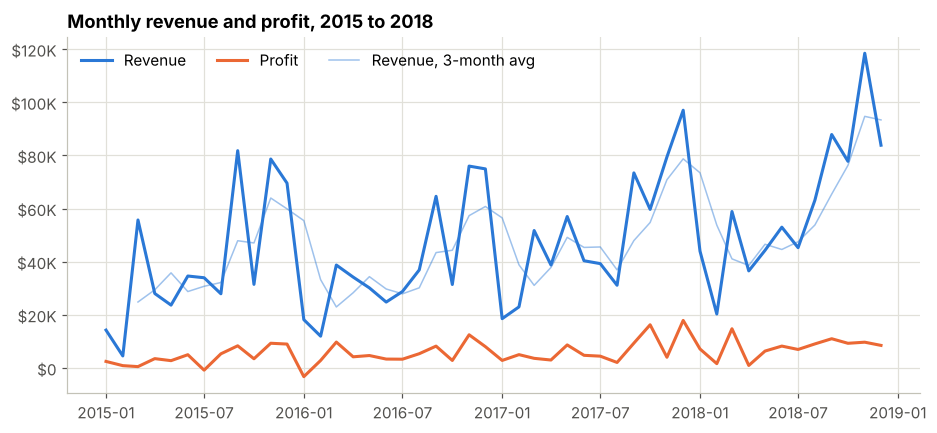

In [12]:
monthly = df.groupby("Order Month")[["Sales", "Profit"]].sum()
fig, ax = plt.subplots()
ax.plot(monthly.index, monthly["Sales"], color=BLUE, lw=2, label="Revenue")
ax.plot(monthly.index, monthly["Profit"], color=ORANGE, lw=2, label="Profit")
ax.plot(monthly.index, monthly["Sales"].rolling(3).mean(), color=BLUE, lw=1, alpha=.45, label="Revenue, 3-month avg")
ax.yaxis.set_major_formatter(money)
ax.set_title("Monthly revenue and profit, 2015 to 2018")
ax.legend(frameon=False, ncol=3, loc="upper left")
fig.savefig(IMG / "monthly_trend.png")
plt.show()

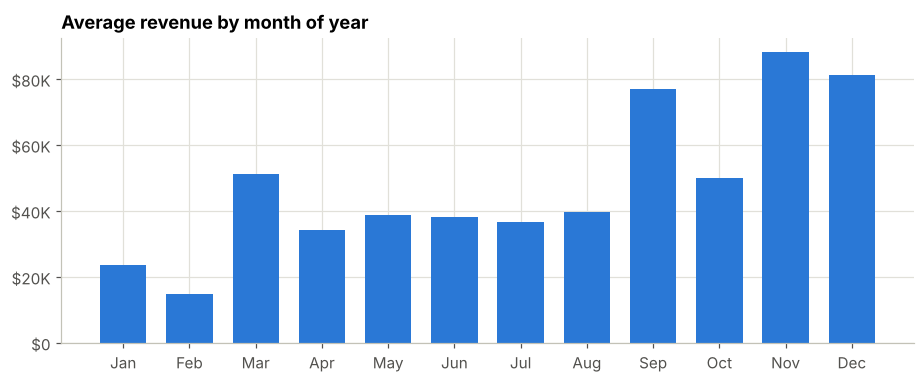

Sep to Dec share of annual revenue: 51.6%


In [13]:
season = df.groupby("Month")["Sales"].sum() / 4
share = season / season.sum()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(season.index, season.values, color=BLUE, width=.7)
ax.set_xticks(range(1, 13), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.yaxis.set_major_formatter(money)
ax.set_title("Average revenue by month of year")
fig.savefig(IMG / "seasonality.png")
plt.show()
print(f"Sep to Dec share of annual revenue: {share.loc[9:12].sum():.1%}")

In [14]:
weekday = df.groupby("Weekday")["Sales"].sum().reindex(
    ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"])
(weekday / weekday.sum()).to_frame("Share of revenue")

,Share of revenue
Weekday,
Monday,0.16
Tuesday,0.19
Wednesday,0.14
Thursday,0.06
Friday,0.11
Saturday,0.19
Sunday,0.17


## 6. Regional sales analysis

In [15]:
region = df.groupby(["Region", "Regional Manager"]).agg(
    Revenue=("Sales", "sum"), Profit=("Profit", "sum"), Orders=("Order ID", "nunique"),
    Customers=("Customer ID", "nunique")).reset_index()
region["Margin"] = region["Profit"] / region["Revenue"]
region["Revenue share"] = region["Revenue"] / region["Revenue"].sum()
region = region.sort_values("Revenue", ascending=False)
region

,Region,Regional Manager,Revenue,Profit,Orders,Customers,Margin,Revenue share
3,West,Anna Andreadi,"725,457.82","108,418.45",1611,686,0.15,0.32
1,East,Chuck Magee,"678,499.87","91,534.84",1401,674,0.13,0.30
0,Central,Kelly Williams,"501,239.89","39,706.36",1175,629,0.08,0.22
2,South,Cassandra Brandow,"391,721.91","46,749.43",822,512,0.12,0.17


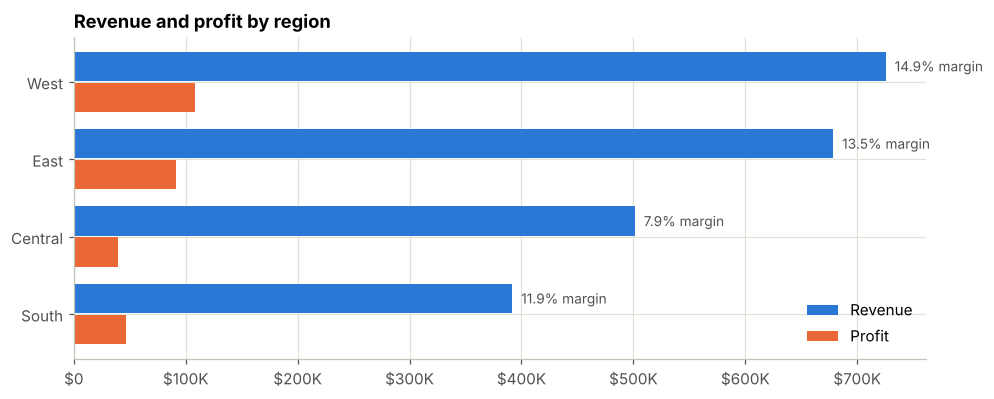

In [16]:
r = region.sort_values("Revenue")
y = np.arange(len(r))
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(y + .2, r["Revenue"], height=.38, color=BLUE, label="Revenue")
ax.barh(y - .2, r["Profit"], height=.38, color=ORANGE, label="Profit")
for i, (rev, m) in enumerate(zip(r["Revenue"], r["Margin"])):
    ax.text(rev + 8000, i + .2, f"{m:.1%} margin", va="center", fontsize=9, color="#52514e")
ax.set_yticks(y, r["Region"])
ax.xaxis.set_major_formatter(money)
ax.set_title("Revenue and profit by region")
ax.legend(frameon=False, loc="lower right")
fig.savefig(IMG / "region.png")
plt.show()

In [17]:
pivot = df.pivot_table(index="Region", columns="Category", values=["Profit", "Sales"], aggfunc="sum")
margin_rc = pivot["Profit"] / pivot["Sales"]
margin_rc.style.format("{:.1%}").background_gradient(cmap="RdBu", vmin=-0.2, vmax=0.2)

Category,Furniture,Office Supplies,Technology
Region,,,
Central,-1.8%,5.3%,19.8%
East,1.5%,20.0%,17.9%
South,5.8%,15.9%,13.4%
West,4.6%,23.8%,17.6%


In [18]:
state = df.groupby("State").agg(Revenue=("Sales", "sum"), Profit=("Profit", "sum"))
state["Margin"] = state["Profit"] / state["Revenue"]
print("Top 10 states by revenue")
display(state.sort_values("Revenue", ascending=False).head(10))
print("10 states with the largest losses")
display(state.sort_values("Profit").head(10))

Top 10 states by revenue


,Revenue,Profit,Margin
State,,,
California,"457,687.63","76,381.39",0.17
New York,"310,876.27","74,038.55",0.24
Texas,"170,188.05","-25,729.36",-0.15
Washington,"138,641.27","33,402.65",0.24
Pennsylvania,"116,511.91","-15,559.96",-0.13
Florida,"89,473.71","-3,399.30",-0.04
Illinois,"80,166.10","-12,607.89",-0.16
Ohio,"77,976.76","-16,959.32",-0.22
Michigan,"76,269.61","24,463.19",0.32


10 states with the largest losses


,Revenue,Profit,Margin
State,,,
Texas,"170,188.05","-25,729.36",-0.15
Ohio,"77,976.76","-16,959.32",-0.22
Pennsylvania,"116,511.91","-15,559.96",-0.13
Illinois,"80,166.10","-12,607.89",-0.16
North Carolina,"55,603.16","-7,490.91",-0.13
Colorado,"32,108.12","-6,527.86",-0.20
Tennessee,"30,661.87","-5,341.69",-0.17
Arizona,"35,282.00","-3,427.92",-0.10
Florida,"89,473.71","-3,399.30",-0.04


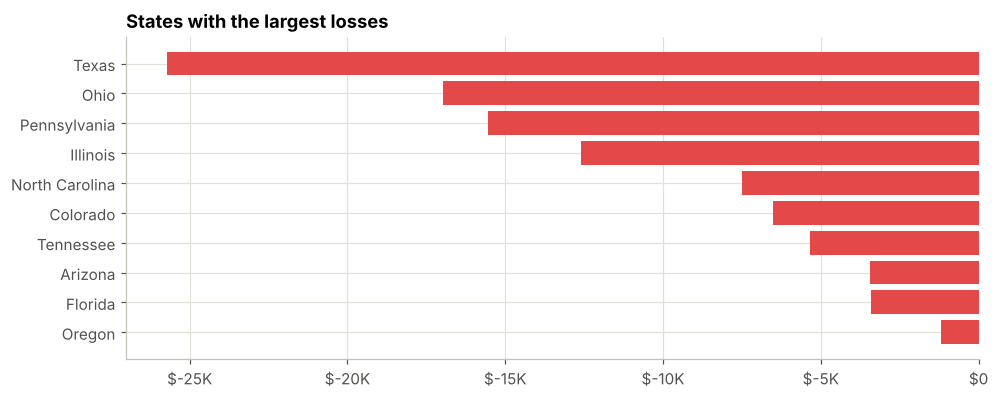

In [19]:
worst = state.sort_values("Profit").head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(worst.index, worst["Profit"], color=[RED if v < 0 else BLUE for v in worst["Profit"]])
ax.xaxis.set_major_formatter(money)
ax.set_title("States with the largest losses")
fig.savefig(IMG / "state_losses.png")
plt.show()

## 7. Product performance

In [20]:
cat = df.groupby("Category").agg(Revenue=("Sales", "sum"), Profit=("Profit", "sum"), Units=("Quantity", "sum"))
cat["Margin"] = cat["Profit"] / cat["Revenue"]
cat["Revenue share"] = cat["Revenue"] / cat["Revenue"].sum()
cat["Profit share"] = cat["Profit"] / cat["Profit"].sum()
cat.sort_values("Revenue", ascending=False)

,Revenue,Profit,Units,Margin,Revenue share,Profit share
Category,,,,,,
Technology,"836,154.03","145,454.95",6939,0.17,0.36,0.51
Furniture,"741,718.42","18,463.33",8026,0.02,0.32,0.06
Office Supplies,"719,047.03","122,490.80",22906,0.17,0.31,0.43


In [21]:
sub = df.groupby(["Category", "Sub-Category"]).agg(Revenue=("Sales", "sum"), Profit=("Profit", "sum"),
                                                   Units=("Quantity", "sum"), AvgDiscount=("Discount", "mean"))
sub["Margin"] = sub["Profit"] / sub["Revenue"]
sub = sub.sort_values("Profit")
sub

Revenue     Profit  Units  AvgDiscount  Margin
Category        Sub-Category                                                  
Furniture       Tables       206,965.53 -17,725.48   1241         0.26   -0.09
                Bookcases    114,880.00  -3,472.56    868         0.21   -0.03
Office Supplies Supplies      46,673.54  -1,189.10    647         0.08   -0.03
                Fasteners      3,024.28     949.52    914         0.08    0.31
Technology      Machines     189,238.63   3,384.76    440         0.31    0.02
Office Supplies Labels        12,486.31   5,546.25   1400         0.07    0.44
                Art           27,118.79   6,527.79   3000         0.07    0.24
                Envelopes     16,476.40   6,964.18    906         0.08    0.42
Furniture       Furnishings   91,705.16  13,059.14   3563         0.14    0.14
Office Supplies Appliances   107,532.16  18,138.01   1729         0.17    0.17
                Storage      223,843.61  21,278.83   3158         0.07    0.10
Furniture       Chairs       328,167.73  26,602.23   2354         0.17    0.08
Office Supplies Binders      203,412.73  30,221.76   5974         0.37    0.15
                Paper         78,479.21  34,053.57   5178         0.07    0.43
Technology      Accessories  167,380.32  41,936.64   2976         0.08    0.25
                Phones       330,007.05  44,515.73   3289         0.15    0.13
                Copiers      149,528.03  55,617.82    234         0.16    0.37

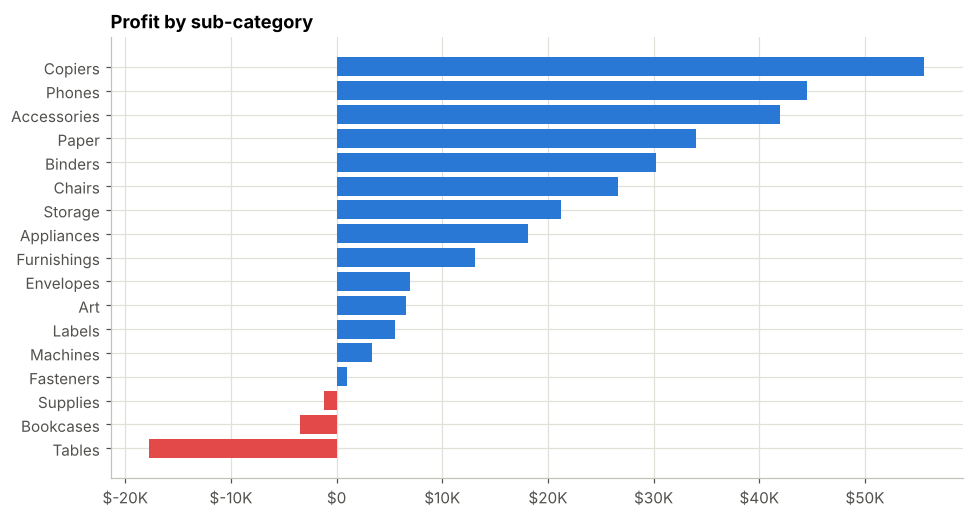

In [22]:
s = sub.reset_index().set_index("Sub-Category")["Profit"]
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.barh(s.index, s.values, color=[RED if v < 0 else BLUE for v in s.values])
ax.xaxis.set_major_formatter(money)
ax.set_title("Profit by sub-category")
fig.savefig(IMG / "subcategory_profit.png")
plt.show()

In [23]:
prod = df.groupby(["Product Name", "Sub-Category"]).agg(
    Revenue=("Sales", "sum"), Profit=("Profit", "sum"), Units=("Quantity", "sum")).reset_index()
prod["Margin"] = prod["Profit"] / prod["Revenue"]
print("Top 10 products by revenue")
display(prod.nlargest(10, "Revenue"))
print("Top 10 products by profit")
display(prod.nlargest(10, "Profit"))
print("10 biggest loss-making products")
display(prod.nsmallest(10, "Profit"))

Top 10 products by revenue


,Product Name,Sub-Category,Revenue,Profit,Units,Margin
404,Canon imageCLASS 2200 Advanced Copier,Copiers,"61,599.82","25,199.93",20,0.41
650,Fellowes PB500 Electric Punch Plastic Comb Bin...,Binders,"27,453.38","7,753.04",31,0.28
444,Cisco TelePresence System EX90 Videoconferenci...,Machines,"22,638.48","-1,811.08",6,-0.08
786,HON 5400 Series Task Chairs for Big and Tall,Chairs,"21,870.58",0.00,39,0.00
686,GBC DocuBind TL300 Electric Binding System,Binders,"19,823.48","2,233.51",37,0.11
688,GBC Ibimaster 500 Manual ProClick Binding System,Binders,"19,024.50",760.98,48,0.04
805,Hewlett Packard LaserJet 3310 Copier,Copiers,"18,839.69","6,983.88",38,0.37
787,HP Designjet T520 Inkjet Large Format Printer ...,Machines,"18,374.90","4,094.98",12,0.22
683,GBC DocuBind P400 Electric Binding System,Binders,"17,965.07","-1,878.17",27,-0.10
813,High Speed Automatic Electric Letter Opener,Supplies,"17,030.31",-262.00,11,-0.02


Top 10 products by profit


,Product Name,Sub-Category,Revenue,Profit,Units,Margin
404,Canon imageCLASS 2200 Advanced Copier,Copiers,"61,599.82","25,199.93",20,0.41
650,Fellowes PB500 Electric Punch Plastic Comb Bin...,Binders,"27,453.38","7,753.04",31,0.28
805,Hewlett Packard LaserJet 3310 Copier,Copiers,"18,839.69","6,983.88",38,0.37
400,Canon PC1060 Personal Laser Copier,Copiers,"11,619.83","4,570.93",19,0.39
787,HP Designjet T520 Inkjet Large Format Printer ...,Machines,"18,374.90","4,094.98",12,0.22
165,Ativa V4110MDD Micro-Cut Shredder,Machines,"7,699.89","3,772.95",11,0.49
19,"3D Systems Cube Printer, 2nd Generation, Magenta",Machines,"14,299.89","3,717.97",11,0.26
1276,Plantronics Savi W720 Multi-Device Wireless He...,Accessories,"9,367.29","3,696.28",24,0.39
895,Ibico EPK-21 Electric Binding System,Binders,"15,875.92","3,345.28",13,0.21
1840,Zebra ZM400 Thermal Label Printer,Machines,"6,965.70","3,343.54",6,0.48


10 biggest loss-making products


,Product Name,Sub-Category,Revenue,Profit,Units,Margin
475,Cubify CubeX 3D Printer Double Head Print,Machines,"11,099.96","-8,879.97",9,-0.80
985,Lexmark MX611dhe Monochrome Laser Printer,Machines,"16,829.90","-4,589.97",18,-0.27
476,Cubify CubeX 3D Printer Triple Head Print,Machines,"7,999.98","-3,839.99",4,-0.48
425,Chromcraft Bull-Nose Wood Oval Conference Tabl...,Tables,"9,917.64","-2,876.12",27,-0.29
376,Bush Advantage Collection Racetrack Conference...,Tables,"9,544.73","-1,934.40",33,-0.20
683,GBC DocuBind P400 Electric Binding System,Binders,"17,965.07","-1,878.17",27,-0.10
444,Cisco TelePresence System EX90 Videoconferenci...,Machines,"22,638.48","-1,811.08",6,-0.08
1043,Martin Yale Chadless Opener Electric Letter Op...,Supplies,"16,656.20","-1,299.18",22,-0.08
285,Balt Solid Wood Round Tables,Tables,"6,518.75","-1,201.06",19,-0.18
364,BoxOffice By Design Rectangular and Half-Moon ...,Tables,"1,706.25","-1,148.44",15,-0.67


In [24]:
# Pareto: how concentrated is revenue across products?
p = prod.sort_values("Revenue", ascending=False)
cum = p["Revenue"].cumsum() / p["Revenue"].sum()
top20 = int(len(p) * 0.2)
print(f"{len(p):,} products. Top 20% ({top20}) generate {cum.iloc[top20-1]:.1%} of revenue.")

1,850 products. Top 20% (370) generate 76.8% of revenue.


## 8. Customer purchasing behaviour

In [25]:
seg = df.groupby("Segment").agg(Revenue=("Sales", "sum"), Profit=("Profit", "sum"),
                                Customers=("Customer ID", "nunique"), Orders=("Order ID", "nunique"))
seg["Margin"] = seg["Profit"] / seg["Revenue"]
seg["Revenue per customer"] = seg["Revenue"] / seg["Customers"]
seg["Avg order value"] = seg["Revenue"] / seg["Orders"]
seg

,Revenue,Profit,Customers,Orders,Margin,Revenue per customer,Avg order value
Segment,,,,,,,
Consumer,"1,161,401.34","134,119.21",409,2586,0.12,"2,839.61",449.11
Corporate,"706,146.37","91,979.13",236,1514,0.13,"2,992.15",466.41
Home Office,"429,371.78","60,310.74",148,909,0.14,"2,901.16",472.36


In [26]:
cust = df.groupby(["Customer ID", "Customer Name", "Segment"]).agg(
    Orders=("Order ID", "nunique"), Revenue=("Sales", "sum"), Profit=("Profit", "sum"),
    First=("Order Date", "min"), Last=("Order Date", "max")).reset_index()
print(f"Customers: {len(cust)}")
print(f"Repeat customers (2+ orders): {(cust['Orders'] > 1).mean():.1%}")
print(f"Median orders per customer: {cust['Orders'].median():.0f}")
top20c = cust.nlargest(int(len(cust) * .2), "Revenue")["Revenue"].sum() / cust["Revenue"].sum()
print(f"Top 20% of customers generate {top20c:.1%} of revenue")
print(f"Customers with negative lifetime profit: {(cust['Profit'] < 0).sum()}")

Customers: 793
Repeat customers (2+ orders): 98.5%
Median orders per customer: 6
Top 20% of customers generate 48.0% of revenue
Customers with negative lifetime profit: 155


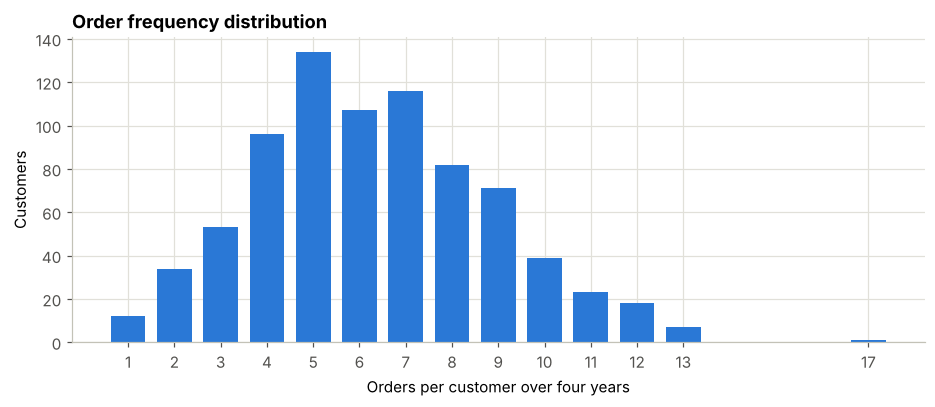

In [27]:
fig, ax = plt.subplots(figsize=(10, 3.6))
counts = cust["Orders"].value_counts().sort_index()
ax.bar(counts.index, counts.values, color=BLUE, width=.75)
ax.set_xlabel("Orders per customer over four years"); ax.set_ylabel("Customers")
ax.set_xticks(counts.index)
ax.set_title("Order frequency distribution")
fig.savefig(IMG / "order_frequency.png")
plt.show()

In [28]:
# RFM segmentation (recency, frequency, monetary) on a 1-4 quartile scale.
snapshot = df["Order Date"].max() + pd.Timedelta(days=1)
rfm = cust.assign(Recency=(snapshot - cust["Last"]).dt.days)
rfm["R"] = pd.qcut(rfm["Recency"], 4, labels=[4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm["Orders"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
rfm["M"] = pd.qcut(rfm["Revenue"], 4, labels=[1, 2, 3, 4]).astype(int)

def label(row):
    if row.R >= 3 and row.F >= 3 and row.M >= 3: return "Champions"
    if row.F >= 3 and row.M >= 3: return "Loyal, slipping"
    if row.R >= 3: return "Recent / promising"
    if row.R <= 1 and row.M >= 3: return "At risk, high value"
    return "Low engagement"

rfm["RFM segment"] = rfm.apply(label, axis=1)
rfm_summary = rfm.groupby("RFM segment").agg(Customers=("Customer ID", "count"), Revenue=("Revenue", "sum"),
                                             AvgOrders=("Orders", "mean"), AvgRecencyDays=("Recency", "mean"))
rfm_summary["Revenue share"] = rfm_summary["Revenue"] / rfm_summary["Revenue"].sum()
rfm.to_csv(ROOT / "data/processed/customer_rfm.csv", index=False, date_format="%Y-%m-%d")
rfm_summary.sort_values("Revenue", ascending=False)

,Customers,Revenue,AvgOrders,AvgRecencyDays,Revenue share
RFM segment,,,,,
Champions,176,"802,935.47",8.81,33.23,0.35
"Loyal, slipping",107,"530,408.26",8.31,170.61,0.23
Recent / promising,221,"456,236.46",5.43,33.87,0.20
Low engagement,255,"358,182.87",4.75,277.71,0.16
"At risk, high value",34,"149,156.43",4.71,434.65,0.06


In [29]:
ship = df.groupby("Ship Mode").agg(Orders=("Order ID", "nunique"), AvgDaysToShip=("Days to Ship", "mean"),
                                   Revenue=("Sales", "sum"))
ship["Order share"] = ship["Orders"] / ship["Orders"].sum()
ship.sort_values("Orders", ascending=False)

,Orders,AvgDaysToShip,Revenue,Order share
Ship Mode,,,,
Standard Class,2994,5.01,"1,357,934.37",0.60
Second Class,964,3.24,"459,193.57",0.19
First Class,787,2.18,"351,428.42",0.16
Same Day,264,0.04,"128,363.12",0.05


## 9. Discounts and profitability

In [30]:
disc = df.groupby("Discount Band", observed=True).agg(Lines=("Sales", "size"), Revenue=("Sales", "sum"),
                                                      Profit=("Profit", "sum"))
disc["Margin"] = disc["Profit"] / disc["Revenue"]
disc = disc.reindex(["No discount", "1-20%", "21-40%", "41-80%"])
disc

,Lines,Revenue,Profit,Margin
Discount Band,,,,
No discount,4798,"1,087,908.47","320,987.60",0.30
1-20%,3803,"846,522.24","100,785.47",0.12
21-40%,459,"233,856.53","-35,805.41",-0.15
41-80%,933,"128,632.25","-99,558.59",-0.77


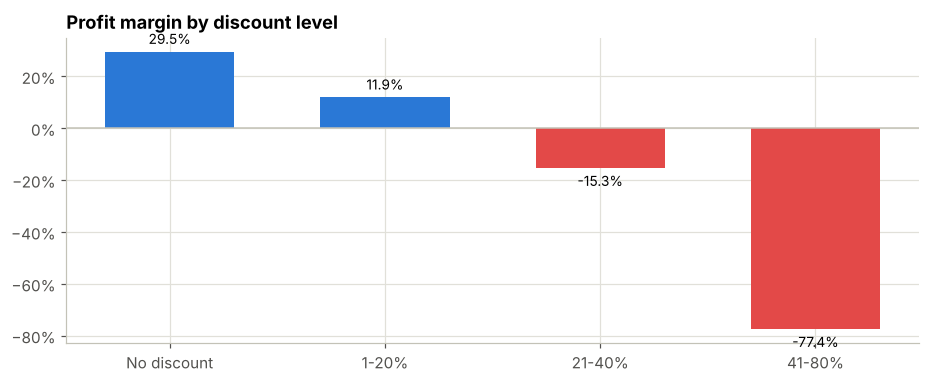

Correlation between discount and profit margin: -0.86


In [31]:
fig, ax = plt.subplots(figsize=(10, 3.6))
bars = ax.bar(disc.index, disc["Margin"], color=[RED if v < 0 else BLUE for v in disc["Margin"]], width=.6)
ax.bar_label(bars, labels=[f"{v:.1%}" for v in disc["Margin"]], padding=3, fontsize=9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.axhline(0, color="#c3c2b7", lw=1)
ax.set_title("Profit margin by discount level")
fig.savefig(IMG / "discount_margin.png")
plt.show()
print(f"Correlation between discount and profit margin: {df['Discount'].corr(df['Profit Margin']):.2f}")

In [32]:
# Where do the deep discounts happen?
deep = df[df["Discount"] > 0.2]
deep.groupby(["Region", "Sub-Category"])["Profit"].sum().nsmallest(10).to_frame("Profit lost")

Profit lost
Region  Sub-Category             
Central Binders        -21,909.40
East    Machines       -13,990.19
        Tables         -11,025.38
South   Tables          -8,840.78
Central Appliances      -8,629.64
South   Binders         -8,404.47
        Machines        -7,635.23
Central Tables          -6,526.42
East    Phones          -6,385.79
        Binders         -5,971.64

## 10. Business insights and recommendations

**What the data shows**

1. **Healthy growth.** Revenue grew 51% from \$484K (2015) to \$733K (2018), a 14.9% CAGR. Profit grew
   faster, \$49.6K to \$93.4K, after 2015's 10.2% margin improved to about 13%.
2. **Discounting is the main profit leak.** Lines discounted more than 20% produced \$362K of revenue and
   lost \$135K. Undiscounted lines earn a 29.5% margin; lines at 41 to 80% off lose 77 cents per dollar.
3. **Furniture is a volume trap.** It is 32% of revenue but 6% of profit (2.5% margin). Tables lose
   \$17.7K and Bookcases \$3.5K, almost entirely on heavily discounted lines.
4. **Technology and Office Supplies carry profit.** Together 94% of profit. Copiers (37% margin), Phones and
   Accessories are the profit engines; Paper, Labels and Envelopes earn over 40% margin on small revenue.
5. **Central and four states drag margin.** Central earns 7.9% against West's 14.9%. Texas, Ohio,
   Pennsylvania and Illinois lose \$71K between them, driven by deep discounts.
6. **Customers are loyal but concentrated.** 98% of customers ordered more than once; the top 20% of
   customers bring 48% of revenue. Consumers are half of revenue; Home Office has the best margin (14.0%).
7. **Strong seasonality.** September to December generate 52% of annual revenue.

**Recommendations**

* Cap discounts at 20% by default and require approval above it, starting with Tables, Bookcases,
  Binders and Machines in Central and the East's loss states.
* Reprice or bundle Furniture (Tables and Bookcases especially) with accessories, or drop the worst SKUs
  such as the Cubify 3D printers and conference tables that lose money on every sale.
* Push the high-margin lines (Copiers, Accessories, Paper, Labels) in cross-sell and in Q4 campaigns.
* Run a loyalty programme for the top 20% of customers and win-back offers for "At risk, high value"
  RFM customers.
* Plan inventory, staffing and marketing spend around the September to December peak.